# 04 — Analyses : questions Q1 à Q6

| Question | Indicateur | Méthode | Graphique |
|---|---|---|---|
| Q1 Énergie | apport énergétique (kcal/j) | moyenne et percentiles pondérés, IC 95 % | histogramme |
| Q2 Sexe | apports par sexe | comparaison des moyennes pondérées | barres |
| Q3 Âge | apports par classe d'âge | moyennes pondérées + régression pondérée | courbes |
| Q4 Densité | apport pour 1 000 kcal | rapport nutriment / énergie | barres |
| Q5 Contributeurs | % de l'apport par groupe d'aliments | ratio des moyennes | barres empilées |
| Q6 Variabilité | médiane, P5-P95 | percentiles pondérés | violin plot |
| Sous-déclaration | apport / métabolisme de base | critère de Goldberg | histogramme |

Toutes les estimations sont **pondérées** (`pond_indiv_adu_pop3`) et portent sur les 2 121 adultes de 18-79 ans.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # pour importer le code de src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nutrihfr import config as C

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
C.DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)
C.DOSSIER_TABLES.mkdir(parents=True, exist_ok=True)

In [2]:
from nutrihfr.pipeline import ChargeurINCA3, CalculApports
from nutrihfr.stats import (resume_pondere, contributions, regression_ponderee,
                            metabolisme_base, seuil_goldberg, variance_intra_inter)

individus, consommations, _ = ChargeurINCA3().charger()
calcul = CalculApports(consommations, individus)
df = calcul.par_individu()          # une ligne par adulte : apports journaliers
lignes = calcul.par_ligne()         # une ligne par aliment consommé : apport de la ligne
NUT = list(C.NUTRIMENTS)
LIB = {n: f"{v[0]} ({v[1]}/j)" for n, v in C.NUTRIMENTS.items()}

## Q1 — Distribution de l'apport énergétique

In [3]:
q1 = pd.concat([resume_pondere(df, "aet").assign(sexe="Ensemble"), resume_pondere(df, "aet", par="sexe")])
q1 = q1.set_index("sexe").round(0)
q1.to_csv(C.DOSSIER_TABLES / "Q1_energie.csv")
q1

,n,moyenne,ic95_bas,ic95_haut,P5,P25,mediane,P75,P95
sexe,,,,,,,,,
Ensemble,"2,121.00","2,102.00","2,048.00","2,157.00","1,047.00","1,547.00","2,014.00","2,565.00","3,358.00"
Femme,"1,234.00","1,787.00","1,738.00","1,836.00",942.00,"1,368.00","1,723.00","2,165.00","2,783.00"
Homme,887.00,"2,438.00","2,356.00","2,519.00","1,251.00","1,904.00","2,386.00","2,932.00","3,842.00"


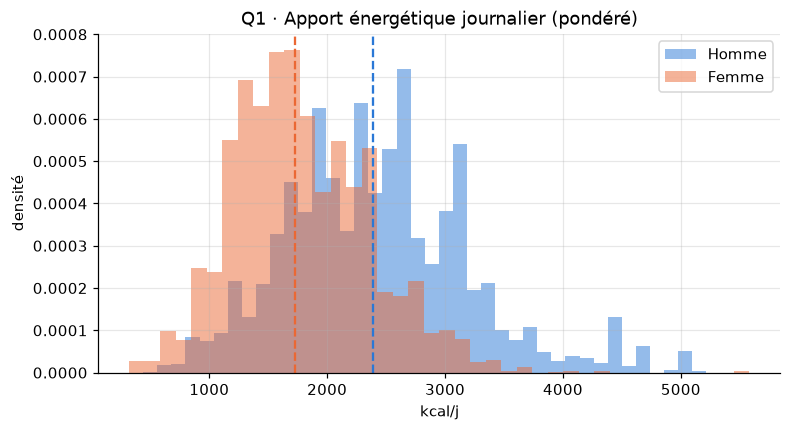

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for sexe, couleur in C.COULEURS_SEXE.items():
    d = df[df["sexe"] == sexe]
    ax.hist(d["aet"], bins=40, weights=d["ponderation"], density=True, alpha=0.5, color=couleur, label=sexe)
    ax.axvline(q1.loc[sexe, "mediane"], color=couleur, ls="--")
ax.set(title="Q1 · Apport énergétique journalier (pondéré)", xlabel="kcal/j", ylabel="densité")
ax.legend()
plt.savefig(C.DOSSIER_FIGURES / "Q1_energie.png", bbox_inches="tight")
plt.show()

**À retenir** — Rédiger avec les chiffres du tableau : apport moyen (et son IC 95 %), médiane, écart hommes/femmes. Les pointillés indiquent les médianes.

## Q2 — Différences entre hommes et femmes

In [5]:
q2 = []
for n in NUT:
    r = resume_pondere(df, n, par="sexe").set_index("sexe")
    q2.append({"nutriment": LIB[n],
               "Femmes": r.loc["Femme", "moyenne"], "IC Femmes": f"{r.loc['Femme', 'ic95_bas']:.1f} - {r.loc['Femme', 'ic95_haut']:.1f}",
               "Hommes": r.loc["Homme", "moyenne"], "IC Hommes": f"{r.loc['Homme', 'ic95_bas']:.1f} - {r.loc['Homme', 'ic95_haut']:.1f}",
               "écart F/H (%)": 100 * (r.loc["Femme", "moyenne"] / r.loc["Homme", "moyenne"] - 1)})
q2 = pd.DataFrame(q2).set_index("nutriment")
q2.to_csv(C.DOSSIER_TABLES / "Q2_sexe.csv")
q2

,Femmes,IC Femmes,Hommes,IC Hommes,écart F/H (%)
nutriment,,,,,
Énergie (kcal/j),"1,786.98",1738.0 - 1836.0,"2,437.55",2355.7 - 2519.4,-26.69
Protéines (g/j),71.08,69.3 - 72.9,95.92,92.1 - 99.8,-25.89
Glucides (g/j),204.57,197.3 - 211.8,277.38,266.9 - 287.8,-26.25
Fibres (g/j),17.71,17.1 - 18.3,21.62,20.9 - 22.3,-18.08
Lipides (g/j),67.12,65.0 - 69.3,86.04,82.6 - 89.4,-21.99
Alcool (g/j),5.06,4.4 - 5.8,16.60,13.5 - 19.7,-69.50
Calcium (mg/j),839.59,807.5 - 871.7,"1,024.38",976.8 - 1072.0,-18.04
Fer (mg/j),8.87,8.6 - 9.1,12.18,11.6 - 12.8,-27.13
Vitamine C (mg/j),85.47,80.8 - 90.1,95.86,90.6 - 101.2,-10.85


**Lecture** — Si les intervalles de confiance des hommes et des femmes ne se chevauchent pas, la différence est significative. Les hommes ont des apports plus élevés pour presque tous les nutriments, surtout parce qu'ils mangent plus : d'où l'intérêt de Q4 (densité).

## Q3 — Évolution avec l'âge

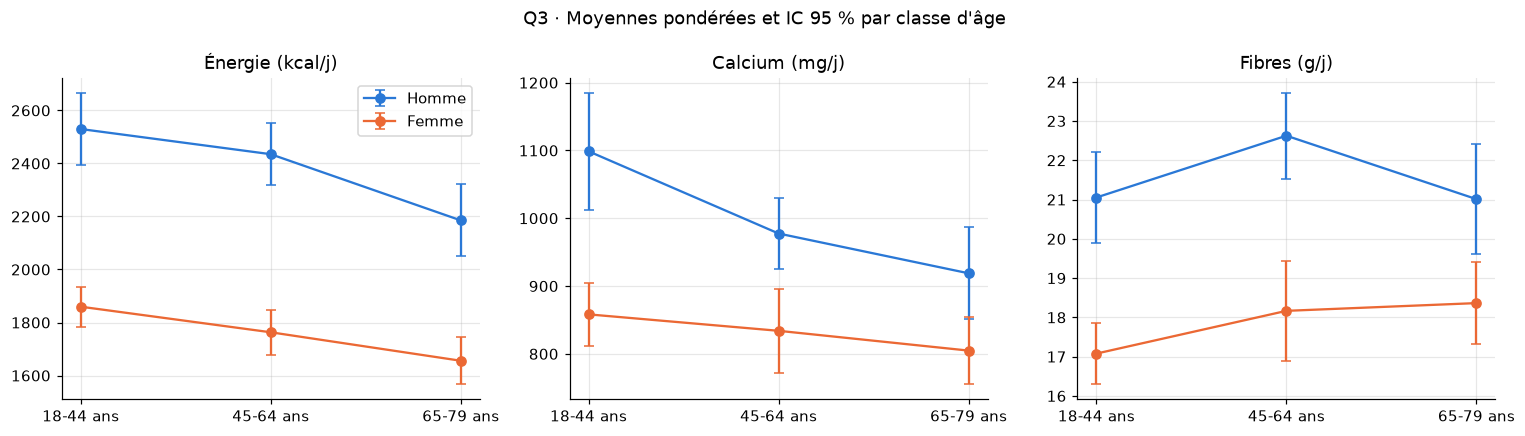

In [6]:
q3 = pd.concat({n: resume_pondere(df, n, par=["sexe", "classe_age"]) for n in NUT}, names=["nutriment"]).reset_index(level=0)
q3.to_csv(C.DOSSIER_TABLES / "Q3_age.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, n in zip(axes, ["aet", "calcium", "fibres"]):
    for sexe, couleur in C.COULEURS_SEXE.items():
        d = q3[(q3["nutriment"] == n) & (q3["sexe"] == sexe)]
        ax.errorbar(d["classe_age"], d["moyenne"], yerr=[d["moyenne"] - d["ic95_bas"], d["ic95_haut"] - d["moyenne"]],
                    marker="o", capsize=3, color=couleur, label=sexe)
    ax.set(title=LIB[n])
axes[0].legend()
plt.suptitle("Q3 · Moyennes pondérées et IC 95 % par classe d'âge")
plt.tight_layout()
plt.savefig(C.DOSSIER_FIGURES / "Q3_age.png", bbox_inches="tight")
plt.show()

**Régression pondérée** `apport ~ sexe + classe d'âge` : elle mesure l'effet de l'âge *à sexe égal*. Référence = une femme de 18-44 ans ; chaque coefficient est une différence en unités du nutriment.

In [7]:
reg = regression_ponderee(df, "aet", ["sexe", "classe_age"])
reg.round(1)

,coefficient,ic95_bas,ic95_haut
constante,"1,871.50","1,819.70","1,923.40"
sexe_Homme,646.10,587.70,704.50
classe_age_45-64 ans,-95.90,-160.60,-31.20
classe_age_65-79 ans,-269.50,-351.40,-187.60


**À retenir** — Par exemple : « à sexe égal, les 65-79 ans consomment X kcal/j de moins que les 18-44 ans (IC 95 % : …) ». Refaire la régression pour un autre nutriment en changeant `"aet"`.

## Q4 — Densité nutritionnelle (pour 1 000 kcal)

In [8]:
for n in NUT[1:]:
    df[n + "_1000kcal"] = df[n] / df["aet"] * 1000

q4 = []
for n in NUT[1:]:
    r = resume_pondere(df, n + "_1000kcal", par="sexe").set_index("sexe")["moyenne"]
    q4.append({"nutriment": f"{C.NUTRIMENTS[n][0]} ({C.NUTRIMENTS[n][1]}/1000 kcal)", "Femmes": r["Femme"],
               "Hommes": r["Homme"], "écart F/H (%)": 100 * (r["Femme"] / r["Homme"] - 1)})
q4 = pd.DataFrame(q4).set_index("nutriment")
q4.to_csv(C.DOSSIER_TABLES / "Q4_densite.csv")
q4

,Femmes,Hommes,écart F/H (%)
nutriment,,,
Protéines (g/1000 kcal),40.97,40.31,1.65
Glucides (g/1000 kcal),113.72,113.55,0.15
Fibres (g/1000 kcal),10.08,9.11,10.62
Lipides (g/1000 kcal),37.33,35.17,6.15
Alcool (g/1000 kcal),2.78,6.46,-56.95
Calcium (mg/1000 kcal),480.46,432.62,11.06
Fer (mg/1000 kcal),5.06,5.03,0.63
Vitamine C (mg/1000 kcal),50.01,41.27,21.19


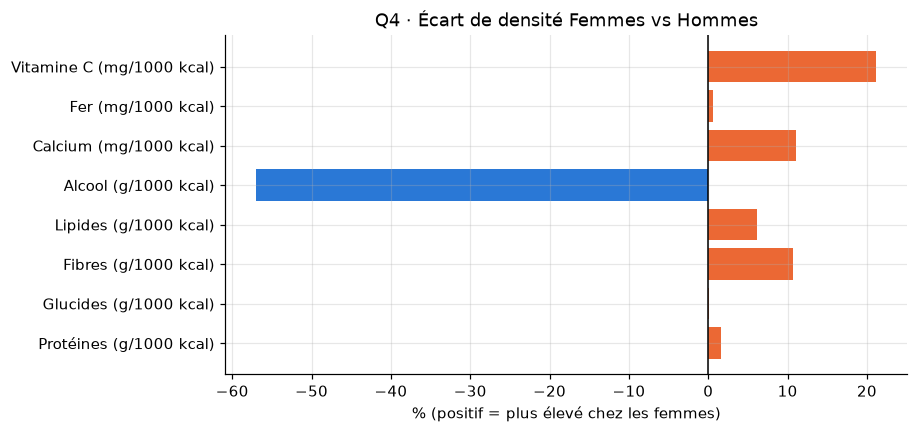

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
couleurs = [C.COULEURS_SEXE["Femme"] if v > 0 else C.COULEURS_SEXE["Homme"] for v in q4["écart F/H (%)"]]
ax.barh(q4.index, q4["écart F/H (%)"], color=couleurs)
ax.axvline(0, color="black", lw=1)
ax.set(title="Q4 · Écart de densité Femmes vs Hommes", xlabel="% (positif = plus élevé chez les femmes)")
plt.savefig(C.DOSSIER_FIGURES / "Q4_densite.png", bbox_inches="tight")
plt.show()

**À retenir** — À énergie égale, les écarts entre hommes et femmes changent souvent de sens par rapport à Q2 : c'est ce qui distingue « manger plus » de « manger différemment ».

## Q5 — Principaux aliments contributeurs

Contribution d'un groupe = somme pondérée des apports venant de ce groupe / somme pondérée des apports totaux (**ratio des moyennes**). C'est la réponse à « d'où vient le calcium consommé par la population ? ». L'autre méthode, la moyenne des ratios individuels, donnerait le même poids à chaque personne quel que soit son apport, et serait instable pour les petits consommateurs.

In [10]:
q5 = pd.DataFrame({n: contributions(lignes, df, n) for n in C.NUTRIMENTS_Q5}).fillna(0)
q5.to_csv(C.DOSSIER_TABLES / "Q5_contributeurs.csv")
for n in C.NUTRIMENTS_Q5:
    top = q5[n].sort_values(ascending=False).head(3)
    print(f"{C.NUTRIMENTS[n][0]:<11}: " + " | ".join(f"{g} {v:.0f} %" for g, v in top.items()))

Protéines  : Viandes (hors volailles) 15 % | Pain et panification raffinés 11 % | Volailles 8 %
Calcium    : Fromages 18 % | Yaourts et fromages blancs 10 % | Laits 10 %
Fer        : Pain et panification raffinés 13 % | Viandes (hors volailles) 9 % | Viennoiseries, pâtisseries, biscuits sucrés 7 %
Fibres     : Pain et panification raffinés 18 % | Légumes 15 % | Fruits frais et secs 12 %
Vitamine C : Fruits frais et secs 31 % | Jus de fruits et de légumes 18 % | Légumes 18 %


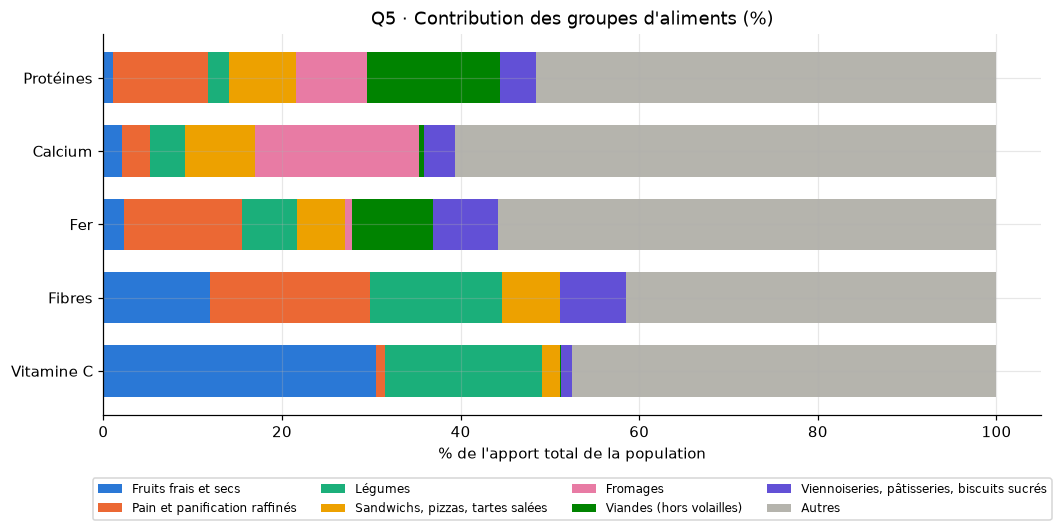

In [11]:
principaux = q5.mean(axis=1).sort_values(ascending=False).index[:7]   # 7 groupes + "Autres"
empile = q5.loc[principaux].T
empile["Autres"] = 100 - empile.sum(axis=1)
empile.index = [C.NUTRIMENTS[n][0] for n in empile.index]

ax = empile.plot.barh(stacked=True, figsize=(11, 4.5), color=C.PALETTE[:7] + ["#b5b4ad"], width=0.7)
ax.invert_yaxis()
ax.set(title="Q5 · Contribution des groupes d'aliments (%)", xlabel="% de l'apport total de la population")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.15), fontsize=8)
plt.savefig(C.DOSSIER_FIGURES / "Q5_contributeurs.png", bbox_inches="tight")
plt.show()

## Q6 — Variabilité entre individus (exemple : femmes de 18-44 ans)

In [12]:
femmes = df[(df["sexe"] == "Femme") & (df["classe_age"] == "18-44 ans")]
q6 = pd.concat({LIB[n]: resume_pondere(femmes, n).iloc[0] for n in NUT}, axis=1).T
q6.to_csv(C.DOSSIER_TABLES / "Q6_variabilite.csv")
print(f"Femmes 18-44 ans : n = {len(femmes)}")
q6[["moyenne", "P5", "P25", "mediane", "P75", "P95"]]

Femmes 18-44 ans : n = 459


,moyenne,P5,P25,mediane,P75,P95
Énergie (kcal/j),"1,859.67",975.28,"1,398.79","1,810.83","2,237.75","2,891.76"
Protéines (g/j),70.39,41.63,57.14,67.09,83.39,108.71
Glucides (g/j),215.40,100.46,154.59,213.66,267.09,347.20
Fibres (g/j),17.08,7.91,12.72,16.52,21.05,27.54
Lipides (g/j),71.11,34.63,49.99,67.98,85.35,125.22
Alcool (g/j),4.86,0.00,0.00,0.10,6.55,21.78
Calcium (mg/j),858.27,374.85,592.23,809.33,"1,041.56","1,566.58"
Fer (mg/j),9.10,4.45,6.82,8.85,10.94,14.80
Vitamine C (mg/j),77.68,18.26,39.31,67.43,103.00,172.57


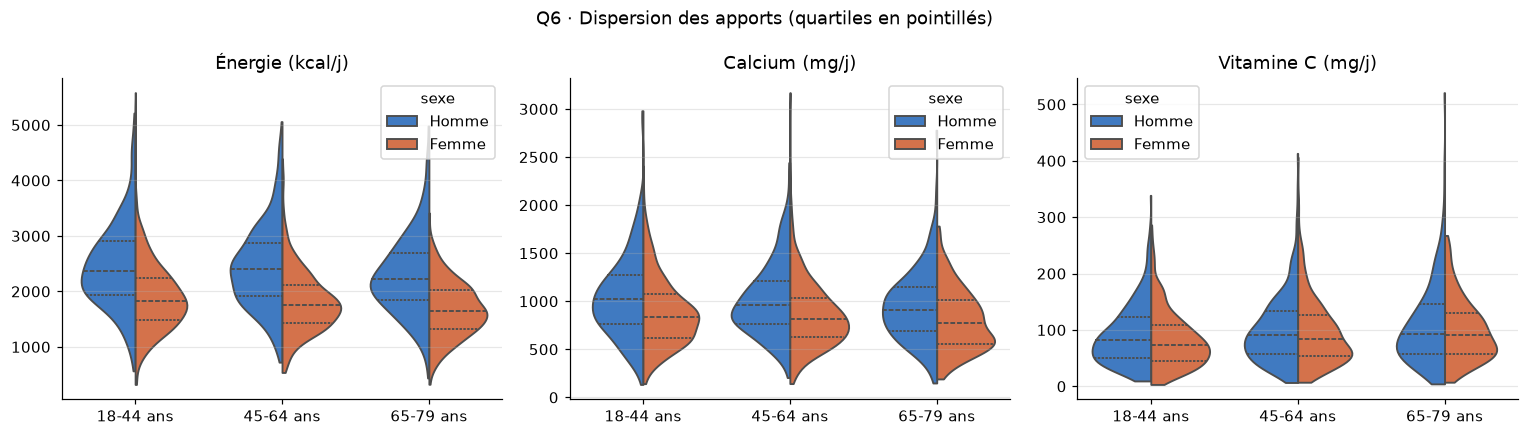

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, n in zip(axes, ["aet", "calcium", "vitamine_c"]):
    sns.violinplot(data=df, x="classe_age", y=n, hue="sexe", split=True, inner="quartile",
                   palette=C.COULEURS_SEXE, cut=0, ax=ax)
    ax.set(title=LIB[n], xlabel="", ylabel="")
plt.suptitle("Q6 · Dispersion des apports (quartiles en pointillés)")
plt.tight_layout()
plt.savefig(C.DOSSIER_FIGURES / "Q6_violin.png", bbox_inches="tight")
plt.show()

**Attention** : avec seulement 2-3 jours par personne, une partie de la dispersion vient des variations d'un jour à l'autre chez une même personne (variabilité *intra*-individuelle). La notice INCA 3 (§ 2.2.1) précise que la moyenne et la médiane sont robustes, mais que P5 est sous-estimé et P95 surestimé. On mesure la part de variance vraiment due aux différences entre personnes :

In [14]:
jours = calcul.par_jour()
jours_f = jours[jours["NOIND"].isin(femmes["NOIND"])]
pd.DataFrame({LIB[n]: variance_intra_inter(jours_f, n) for n in NUT}).T[["part_inter_%"]].round(0)

,part_inter_%
Énergie (kcal/j),43.00
Protéines (g/j),34.00
Glucides (g/j),44.00
Fibres (g/j),37.00
Lipides (g/j),35.00
Alcool (g/j),21.00
Calcium (mg/j),40.00
Fer (mg/j),23.00
Vitamine C (mg/j),27.00


## Sous-déclaration (critère de Goldberg)

Une personne qui déclare manger moins que ce que son corps dépense au repos est probablement **sous-déclarante**.
- **Métabolisme de base (MB)** estimé par les équations de Schofield (sexe, âge, poids) ; l'âge est approché par le milieu de la classe.
- **Seuil de Goldberg** (Black, 2000) : il dépend du nombre de jours observés (≈ 1,0 pour 3 jours, en supposant une activité physique modérée, PAL = 1,55).

In [15]:
df["mb"] = [metabolisme_base(s, a, p) if pd.notna(p) else np.nan
            for s, a, p in zip(df["sexe"], df["age_approx"], df["poids"])]
df["ratio_ae_mb"] = df["aet"] / df["mb"]
n_jours = consommations.groupby("NOIND")["R24_nombre"].first()
df["seuil"] = df["NOIND"].map(n_jours).map(seuil_goldberg)
df["sous_declarant"] = (df["ratio_ae_mb"] < df["seuil"]).astype(float)
df.loc[df["mb"].isna(), "sous_declarant"] = np.nan        # poids manquant

prevalence = resume_pondere(df.dropna(subset=["sous_declarant"]), "sous_declarant", par="sexe")
prevalence[["moyenne", "ic95_bas", "ic95_haut"]] *= 100
prevalence[["sexe", "n", "moyenne", "ic95_bas", "ic95_haut"]].rename(columns={"moyenne": "% sous-déclarants"}).round(1)

,sexe,n,% sous-déclarants,ic95_bas,ic95_haut
0,Femme,"1,231.00",30.20,25.80,34.60
1,Homme,885.00,20.00,16.40,23.60


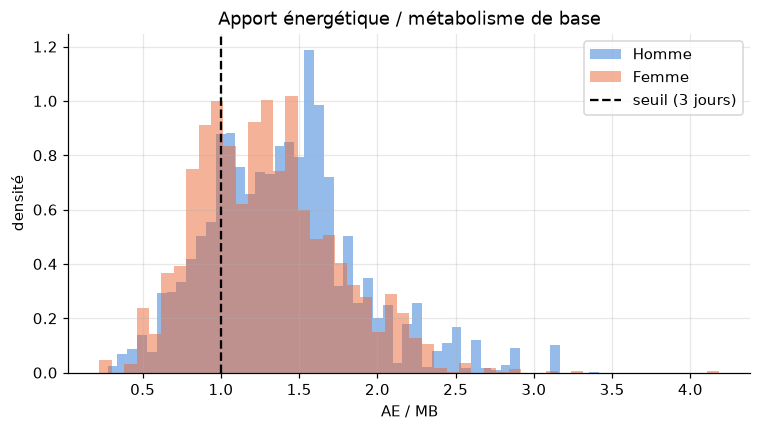

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
for sexe, couleur in C.COULEURS_SEXE.items():
    d = df[df["sexe"] == sexe].dropna(subset=["ratio_ae_mb"])
    ax.hist(d["ratio_ae_mb"], bins=50, weights=d["ponderation"], density=True, alpha=0.5, color=couleur, label=sexe)
ax.axvline(seuil_goldberg(3), color="black", ls="--", label="seuil (3 jours)")
ax.set(title="Apport énergétique / métabolisme de base", xlabel="AE / MB", ylabel="densité")
ax.legend()
plt.savefig(C.DOSSIER_FIGURES / "04_goldberg.png", bbox_inches="tight")
plt.show()

**Robustesse** : les résultats changent-ils si on exclut les sous-déclarants, ou si on oublie de pondérer ?

In [17]:
plausibles = df[df["sous_declarant"] == 0]
non_pondere = df.assign(ponderation=1.0)
robustesse = pd.DataFrame({
    "tous (pondéré)": [resume_pondere(df, n)["moyenne"].iloc[0] for n in NUT],
    "sans sous-déclarants": [resume_pondere(plausibles, n)["moyenne"].iloc[0] for n in NUT],
    "non pondéré": [resume_pondere(non_pondere, n)["moyenne"].iloc[0] for n in NUT],
}, index=[LIB[n] for n in NUT])
robustesse["effet exclusion (%)"] = 100 * (robustesse["sans sous-déclarants"] / robustesse["tous (pondéré)"] - 1)
robustesse["effet pondération (%)"] = 100 * (robustesse["non pondéré"] / robustesse["tous (pondéré)"] - 1)
robustesse.to_csv(C.DOSSIER_TABLES / "robustesse.csv")
robustesse.round(1)

,tous (pondéré),sans sous-déclarants,non pondéré,effet exclusion (%),effet pondération (%)
Énergie (kcal/j),"2,102.40","2,378.00","2,056.80",13.10,-2.20
Protéines (g/j),83.10,91.40,81.10,10.00,-2.40
Glucides (g/j),239.90,272.50,231.00,13.60,-3.70
Fibres (g/j),19.60,21.80,19.80,11.00,1.20
Lipides (g/j),76.30,86.40,76.00,13.20,-0.40
Alcool (g/j),10.70,12.90,10.50,21.30,-1.00
Calcium (mg/j),929.20,"1,020.60",921.60,9.80,-0.80
Fer (mg/j),10.50,11.70,10.30,11.70,-1.70
Vitamine C (mg/j),90.50,98.00,95.40,8.30,5.40


**À retenir** — Exclure les sous-déclarants augmente les apports moyens (attendu). La pondération modifie peu les moyennes mais reste indispensable pour être représentatif. Ce tableau sert d'argument de **robustesse** dans la discussion.

## Traçabilité d'un résultat (annexe C)

Chaque chiffre doit pouvoir être reproduit. Exemple :

In [18]:
import subprocess
m = resume_pondere(femmes, "calcium").iloc[0]
try:
    commit = subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], text=True).strip()
except Exception:
    commit = "non disponible"
print(f"""Calcium moyen = {m.moyenne:.0f} mg/j (IC 95 % : {m.ic95_bas:.0f}-{m.ic95_haut:.0f})
├── Population   : femmes, 18-44 ans (n = {int(m.n)})
├── Source       : INCA 3 (Anses), conso-compo-alim + description-indiv
├── Composition  : fournie par l'Anses pour chaque ligne (pour 100 g)
├── Formule      : qte_conso_pond / 100 x calcium, somme / nombre de jours
├── Agrégation   : moyenne pondérée des apports individuels
├── Pondération  : pond_indiv_adu_pop3
└── Code         : commit Git {commit}""")

Calcium moyen = 858 mg/j (IC 95 % : 812-905)
├── Population   : femmes, 18-44 ans (n = 459)
├── Source       : INCA 3 (Anses), conso-compo-alim + description-indiv
├── Composition  : fournie par l'Anses pour chaque ligne (pour 100 g)
├── Formule      : qte_conso_pond / 100 x calcium, somme / nombre de jours
├── Agrégation   : moyenne pondérée des apports individuels
├── Pondération  : pond_indiv_adu_pop3
└── Code         : commit Git 713415a
